# Generate example platemap figure to represent the plate

## Import libraries

In [1]:
suppressPackageStartupMessages(library(dplyr))
suppressPackageStartupMessages(library(ggplot2))
suppressPackageStartupMessages(library(platetools))


Warning message:
“package ‘ggplot2’ was built under R version 4.2.3”


Warning message:
“package ‘platetools’ was built under R version 4.2.3”


## Set paths

In [2]:
# directory for fig to be outputted
output_dir <- file.path("./platemap_fig")

# Create the output directory if it doesn't exist
if (!dir.exists(output_dir)) {
  dir.create(output_dir, recursive = TRUE)
}

# path to platemap file
platemap_file <- file.path("./platemaps", "pilot_platemap.csv")

# Path for the platemap figure
output_fig <- file.path(output_dir, "pilot_platemap_figure.png")

## Load in platemap file

In [3]:
platemap_df <- readr::read_csv(
    platemap_file,
    col_types = readr::cols(.default = "c")
)

# Label the vehicle wells as control for plotting and remove the "N" from the replicate number
platemap_df <- platemap_df %>%
    dplyr::mutate(
        Treatment = factor(dplyr::recode(Treatment, "Veh" = "Control"), levels = c("Control", "TGFB")),
        well_label = stringr::str_remove(N_Replicate, "^N"),
        WellCol = as.integer(WellCol),
        WellRow = factor(WellRow, levels = rev(LETTERS[1:8]))
    )

print(dim(platemap_df))
head(platemap_df)

[1] 48  6


WellRow,WellCol,well_position,Treatment,N_Replicate,well_label
<fct>,<int>,<chr>,<fct>,<chr>,<chr>
B,3,B03,TGFB,N2,2
B,4,B04,Control,N3,3
B,5,B05,TGFB,N1,1
B,6,B06,TGFB,N4,4
B,7,B07,TGFB,N1,1
B,8,B08,Control,N1,1


## Create platemap figure and save

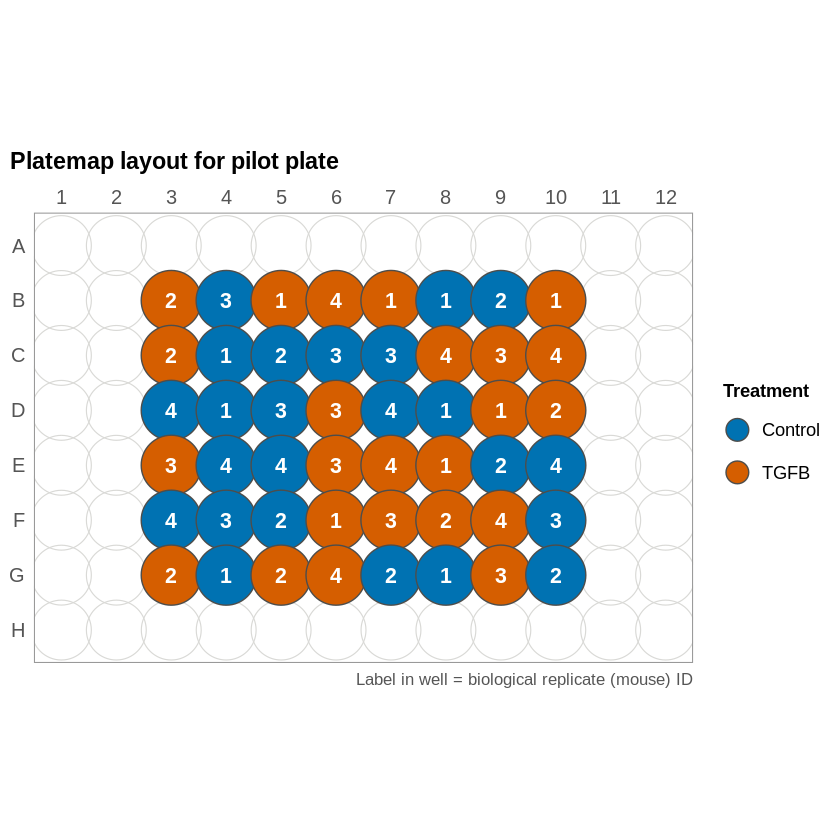

In [4]:
# Consistent color mapping for treatment (Okabe-Ito palette)
treatment_colors <- c(
    "Control" = "#0072B2", # blue
    "TGFB" = "#D55E00"     # vermillion
)

# Wells on the 96-well plate without cells (shown as an empty outline)
empty_wells_df <- expand.grid(WellRow = LETTERS[1:8], WellCol = 1:12) %>%
    dplyr::mutate(WellRow = factor(WellRow, levels = rev(LETTERS[1:8]))) %>%
    dplyr::anti_join(platemap_df, by = c("WellRow", "WellCol"))

# Plot a 96-well platemap where the well color shows the treatment
# and the replicate number is shown inside each well
platemap_gg <- ggplot() +
    geom_point(
        data = empty_wells_df,
        aes(x = WellCol, y = WellRow),
        shape = 21,
        size = 16.5,
        color = "#d9d9d6",
        fill = NA,
        stroke = 0.5
    ) +
    geom_point(
        data = platemap_df,
        aes(x = WellCol, y = WellRow, fill = Treatment),
        shape = 21,
        size = 16.5,
        color = "#4d4d4b",
        stroke = 0.6
    ) +
    geom_text(
        data = platemap_df,
        aes(x = WellCol, y = WellRow, label = well_label),
        color = "white",
        fontface = "bold",
        size = 4.5
    ) +
    scale_fill_manual(name = "Treatment", values = treatment_colors) +
    scale_x_continuous(breaks = 1:12, position = "top", limits = c(0.5, 12.5), expand = c(0, 0)) +
    scale_y_discrete(expand = expansion(add = 0.6), drop = FALSE) +
    coord_fixed() +
    labs(
        title = "Platemap layout for pilot plate",
        caption = "Label in well = biological replicate (mouse) ID",
        x = NULL,
        y = NULL
    ) +
    theme_minimal(base_size = 12) +
    theme(
        plot.title = element_text(size = 14, face = "bold", hjust = 0),
        plot.title.position = "plot",
        plot.caption = element_text(size = 10, color = "#555555", hjust = 1),
        panel.grid = element_blank(),
        panel.border = element_rect(color = "#999999", fill = NA, linewidth = 0.6),
        axis.text = element_text(size = 12, color = "#555555"),
        legend.position = "right",
        legend.title = element_text(size = 11, face = "bold"),
        legend.text = element_text(size = 11),
        legend.key.height = unit(0.9, "cm")
    ) +
    guides(fill = guide_legend(override.aes = list(size = 6)))

ggsave(
    output_fig,
    platemap_gg,
    dpi = 500,
    height = 5.5,
    width = 10.5,
    bg = "white"
)

platemap_gg